# Time mean momentum flux spectra and frequency-integrated momentum fluxes for all Loon data

Author: Brian Green (briangre@stanford.edu)

In [1]:
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import matplotlib.cm
import numpy as np
import pandas as pd
from dataclasses import dataclass
import warnings
from scipy.ndimage import label
from scipy.ndimage import gaussian_filter
from scipy import interpolate
import scipy.signal
from mpl_toolkits.basemap import Basemap
warnings.simplefilter("ignore")

# For determining which times are day or night
import datetime
import pytz
import timezonefinder
import astral, astral.sun
from tqdm.notebook import tqdm

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    tqdm.pandas()
    
# Replace Basemap with Cartopy:
import cartopy.crs as ccrs
import matplotlib.ticker as mticker

### Constants

In [2]:
# Physical constants
g = 9.806 # (m/s**2); acceleration due to gravity
cp = 1005 # (J/kg/K); the specific heat at constant pressure
R = 287 # (J/kg/K); the gas constant for dry air
Omega = 7.27E-5 # (s-1); the rotation rate of the Earth

# Time series properties
dt = 2.0 # (minutes) the time step of the interpolated data

# Thresholds for limiting the size of spectra
GW_PERIOD_MIN = 10 # (minutes) the minimum period for frequency-integrated momentum fluxes
GW_PERIOD_MAX = 1*24*60 # (minutes) the maximum period for GW packets is the minimum of this and the Coriolis period
PERIOD_MAX = 2*24*60 # (minutes) the maximum period for spectrum output

# Wavelet parameters
omega0 = 8 # the normalized Morlet wavelet frequency
dj = 1/24 # Morlet wavelet transform parameter; see Section 3f of Torrence and Compo '98

### Load in the data and mark the depressurizations

In [3]:
flights = pd.read_feather('5_flights_interptime_2daysegments_new_commontime.feather')

# My approach, based on running a few depressurizations through a wavelet analysis, is to mark
# both the depressurization and the data within 2 hours (to the nearsest hour, rounding up) or the 
# width of the depressurization, whichever is bigger, on either side of it.
flights['depressurization'] = 0

# Tropical Pacific
# Segment 284 (Flight I-195)
flights.loc[(flights.flight_id == 'I-195') & 
        (flights.time >= np.datetime64('2014-07-09 07:00:00')) &
        (flights.time <= np.datetime64('2014-07-09 15:00:00')), 'depressurization'] = 1

# Segment 7969 (Flight I-488)
flights.loc[(flights.flight_id == 'I-488') & 
        (flights.time >= np.datetime64('2015-05-21 18:00:00')) &
        (flights.time <= np.datetime64('2015-05-22 10:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'I-488') & 
        (flights.time >= np.datetime64('2015-05-23 04:00:00')) &
        (flights.time <= np.datetime64('2015-05-23 16:00:00')), 'depressurization'] = 1

# Segment 8041 (Flight I-490)
flights.loc[(flights.flight_id == 'I-490') & 
        (flights.time >= np.datetime64('2015-06-24 07:00:00')) &
        (flights.time <= np.datetime64('2015-06-24 13:00:00')), 'depressurization'] = 1



# Tropical Atlantic
# Segment 6506 (Flight I-436)
flights.loc[(flights.flight_id == 'I-436') & 
        (flights.time >= np.datetime64('2015-04-09 01:00:00')) &
        (flights.time <= np.datetime64('2015-04-09 10:00:00')), 'depressurization'] = 1

# Segment 8957 (Flight NR-215)
flights.loc[(flights.flight_id == 'NR-215') & 
        (flights.time >= np.datetime64('2016-02-19 00:00:00')) &
        (flights.time <= np.datetime64('2016-02-19 13:00:00')), 'depressurization'] = 1



# Indian Ocean
# Segment 58 (Flight L-002)
flights.loc[(flights.flight_id == 'L-002') & 
        (flights.time >= np.datetime64('2014-02-15 18:00:00')) &
        (flights.time <= np.datetime64('2014-02-16 04:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'L-002') & 
        (flights.time >= np.datetime64('2014-02-20 04:00:00')) &
        (flights.time <= np.datetime64('2014-02-21 08:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'L-002') & 
        (flights.time >= np.datetime64('2014-02-26 20:00:00')) &
        (flights.time <= np.datetime64('2014-02-27 01:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'L-002') & 
        (flights.time >= np.datetime64('2014-02-28 10:00:00')) &
        (flights.time <= np.datetime64('2014-03-01 04:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'L-002') & 
        (flights.time >= np.datetime64('2014-03-03 04:00:00')) &
        (flights.time <= np.datetime64('2014-03-04 06:00:00')), 'depressurization'] = 1

# Segment 5672 (Flight I-361)
flights.loc[(flights.flight_id == 'I-361') & 
        (flights.time >= np.datetime64('2015-01-26 09:00:00')) &
        (flights.time <= np.datetime64('2015-01-27 09:00:00')), 'depressurization'] = 1



# Extratropical Pacific
# Segment 5782 (Flight I-379)
flights.loc[(flights.flight_id == 'I-379') & 
        (flights.time >= np.datetime64('2014-09-22 02:00:00')) &
        (flights.time <= np.datetime64('2014-09-22 08:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'I-379') & 
        (flights.time >= np.datetime64('2014-09-22 09:00:00')) &
        (flights.time <= np.datetime64('2014-09-22 18:00:00')), 'depressurization'] = 1



# Extratropical Atlantic
# Segment 41 (Flight I-126)
flights.loc[(flights.flight_id == 'I-126') & 
        (flights.time >= np.datetime64('2013-12-23 14:00:00')) &
        (flights.time <= np.datetime64('2013-12-24 03:00:00')), 'depressurization'] = 1



# Southern Ocean
# Segment 543 (Flight I-208)
flights.loc[(flights.flight_id == 'I-208') & 
        (flights.time >= np.datetime64('2014-08-07 23:00:00')) &
        (flights.time <= np.datetime64('2014-08-08 05:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'I-208') & 
        (flights.time >= np.datetime64('2014-08-09 11:00:00')) &
        (flights.time <= np.datetime64('2014-08-10 00:00:00')), 'depressurization'] = 1

# Segment 1303 (Flight I-248)
flights.loc[(flights.flight_id == 'I-248') & 
        (flights.time >= np.datetime64('2014-07-31 22:00:00')) &
        (flights.time <= np.datetime64('2014-08-01 04:00:00')), 'depressurization'] = 1

# Segment 1585 (Flight I-254)
flights.loc[(flights.flight_id == 'I-254') & 
        (flights.time >= np.datetime64('2014-07-31 11:00:00')) &
        (flights.time <= np.datetime64('2014-07-31 17:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'I-254') & 
        (flights.time >= np.datetime64('2014-08-01 06:00:00')) &
        (flights.time <= np.datetime64('2014-08-01 12:00:00')), 'depressurization'] = 1

# Segment 1985 (Flight I-263)
flights.loc[(flights.flight_id == 'I-263') & 
        (flights.time >= np.datetime64('2014-08-02 02:00:00')) &
        (flights.time <= np.datetime64('2014-08-02 21:00:00')), 'depressurization'] = 1

# Segment 2141 (Flight I-267)
flights.loc[(flights.flight_id == 'I-267') & 
        (flights.time >= np.datetime64('2014-09-18 12:00:00')) &
        (flights.time <= np.datetime64('2014-09-18 19:00:00')), 'depressurization'] = 1

# Segment 3559 (Flight I-292)
flights.loc[(flights.flight_id == 'I-292') & 
        (flights.time >= np.datetime64('2014-11-12 05:00:00')) &
        (flights.time <= np.datetime64('2014-11-13 06:00:00')), 'depressurization'] = 1

# Segment 3816 (Flight I-295)
flights.loc[(flights.flight_id == 'I-295') & 
        (flights.time >= np.datetime64('2014-12-01 06:00:00')) &
        (flights.time <= np.datetime64('2014-12-01 13:00:00')), 'depressurization'] = 1

# Segment 3990 (Flight I-296)
flights.loc[(flights.flight_id == 'I-296') & 
        (flights.time >= np.datetime64('2014-12-26 08:00:00')) &
        (flights.time <= np.datetime64('2014-12-26 14:00:00')), 'depressurization'] = 1

# Segment 4060 (Flight I-298)
flights.loc[(flights.flight_id == 'I-298') & 
        (flights.time >= np.datetime64('2014-07-30 03:00:00')) &
        (flights.time <= np.datetime64('2014-07-30 10:00:00')), 'depressurization'] = 1

# Segment 4623 (Flight I-320)
flights.loc[(flights.flight_id == 'I-320') & 
        (flights.time >= np.datetime64('2014-11-02 05:00:00')) &
        (flights.time <= np.datetime64('2014-11-02 19:00:00')), 'depressurization'] = 1

# Segment 4637 (Flight I-320)
flights.loc[(flights.flight_id == 'I-320') & 
        (flights.time >= np.datetime64('2014-11-29 11:00:00')) &
        (flights.time <= np.datetime64('2014-11-29 19:00:00')), 'depressurization'] = 1

# Segment 5216 (Flight I-338)
flights.loc[(flights.flight_id == 'I-338') & 
        (flights.time >= np.datetime64('2014-08-24 04:00:00')) &
        (flights.time <= np.datetime64('2014-08-24 17:00:00')), 'depressurization'] = 1

# Segment 6884 (Flight M-051)
flights.loc[(flights.flight_id == 'M-051') & 
        (flights.time >= np.datetime64('2015-01-25 22:00:00')) &
        (flights.time <= np.datetime64('2015-01-26 10:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'M-051') & 
        (flights.time >= np.datetime64('2015-02-01 19:00:00')) &
        (flights.time <= np.datetime64('2015-02-02 10:00:00')), 'depressurization'] = 1

# Segment 6885 (Flight M-051)
flights.loc[(flights.flight_id == 'M-051') & 
        (flights.time >= np.datetime64('2015-02-05 12:00:00')) &
        (flights.time <= np.datetime64('2015-02-06 09:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'M-051') & 
        (flights.time >= np.datetime64('2015-02-06 15:00:00')) &
        (flights.time <= np.datetime64('2015-02-07 08:00:00')), 'depressurization'] = 1

# Segment 7020 (Flight M-054)
flights.loc[(flights.flight_id == 'M-054') & 
        (flights.time >= np.datetime64('2015-03-31 20:00:00')) &
        (flights.time <= np.datetime64('2015-04-01 08:00:00')), 'depressurization'] = 1
flights.loc[(flights.flight_id == 'M-054') & 
        (flights.time >= np.datetime64('2015-04-02 14:00:00')) &
        (flights.time <= np.datetime64('2015-04-02 22:00:00')), 'depressurization'] = 1


flights

,flight_id,time,latitude,longitude,altitude,pressure,wind_u,wind_v,T_cosmic,dTdz_cosmic,N_cosmic,altitude_spike,segment_id,segment_id_old,depressurization
0,I-027,2013-04-19 21:10:00,38.560904,-113.923499,20586.130007,52.409555,5.868998,-3.926665,-60.174971,0.001718,49.000000,0.0,3,38,0
1,I-027,2013-04-19 21:12:00,38.556831,-113.915264,20611.196773,52.280057,5.787699,-3.533248,-60.131813,0.001728,49.000000,0.0,3,38,0
2,I-027,2013-04-19 21:14:00,38.553290,-113.907235,20581.595870,52.568178,5.646991,-3.188506,-60.182755,0.001716,49.000000,0.0,3,38,0
3,I-027,2013-04-19 21:16:00,38.550114,-113.899945,20606.535630,52.342452,5.485693,-3.143172,-60.142595,0.001726,49.000000,0.0,3,38,0
4,I-027,2013-04-19 21:18:00,38.546757,-113.892468,20581.674482,52.479827,5.664721,-3.223813,-60.096824,0.001688,48.000000,0.0,3,38,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3909563,LN-324,2021-03-08 10:08:00,2.288987,71.312924,19432.212474,59.889808,-0.625520,-1.933254,-69.818583,0.005354,241.999087,0.0,124071,270099,0
3909564,LN-324,2021-03-08 10:10:00,2.287358,71.312195,19473.600113,59.497028,-0.825154,-1.688440,-69.611815,0.005228,240.328892,0.0,124071,270099,0
3909565,LN-324,2021-03-08 10:12:00,2.285122,71.311015,19479.659287,59.425407,-0.913618,-1.497904,-69.580083,0.005213,240.000000,0.0,124071,270099,0
3909566,LN-324,2021-03-08 10:14:00,2.283939,71.310120,19448.613840,59.703928,-0.836494,-1.310828,-69.743248,0.005290,240.000000,0.0,124071,270099,0


In [4]:
flights.flight_id.nunique(), flights.segment_id.nunique(), flights.shape[0]*2/(60*24), flights.latitude.max(), flights.latitude.min()

(391, 943, 5429.955555555555, 79.38862439692265, -78.23931326769893)

### Wavelet analysis function

In [4]:
## WAVELET ANALYSIS
# All equation and table numbers are from Torrence and Compo (1998)

# Create a dataclass for the variables returned from the analysis
@dataclass
class ReturnValue:
    N_pad: float;
    #X_recon: float;
    wave: float;
    #wave_power: float;
    #total_power: float;
    #global_power: float;
    global_power_rescaling: float;
    #total_global_power: float;
    C_delta: float;
    s: float;
    frequency: float;
    period: float;
    coi: float;
    #fftfreq: float;
    #fft: float;
    #fft_power: float;
    #fft_total_power: float;
    #fft_power_rescaling: float;
                    
# The input time series must have a mean of zero
def run_Morlet_CWT(X,dt,omega0,dj):
        
    N = np.size(X)
    std = np.std(X)
    var = std**2

    # Add zero padding and normalize to unit variance
    # The length of the new time series is 2*N for N even, 2*N + 1 for N odd
    N_pad = int(np.ceil(N/2))
    X_norm = np.zeros(N + 2*N_pad)
    X_norm[N_pad:N+N_pad] = X
    X_norm = X_norm/np.std(X_norm)
    N = N + 2*N_pad
    
    # Take the FFT of X_norm and make the frequencies (Eq. 5)
    X_norm_fft = np.fft.fft(X_norm)

    # Calculate the scales and Fourier equivalent frequencies and periods
    s0 = 2*dt*(omega0 + np.sqrt(2 + omega0**2))/(4*np.pi) # An inversion of Table 1 so the shortest period is 2*dt
    J = (1/dj)*np.log2(N*dt/s0) # (Eq. 10)
    J = int(np.ceil(J))
    s = s0*2**(dj*np.arange(J+1)) # (Eq. 9)
    s_tiled = np.tile(s,(N,1)).swapaxes(0,1)
    period = 4*np.pi*s/(omega0 + np.sqrt(2 + omega0**2)) # (Table 1) wavelet equivalent FFT period
    frequency = 1/period
    nscales = s.size
    
    # Loop through the scales to calculate the wavelet transform
    omega = 2*np.pi*np.fft.fftfreq(N)/dt # (Eq. 5) np.fft.fftfreq outputs (0,1,2,...)/N
    wave = np.nan*(1+1j)*np.ones(shape=(nscales,N))
    wave_delta = np.nan*np.ones(nscales)
    for i in np.arange(nscales):
        
        # Calculate the wavelet function (np.heaviside(0,0) = 0, so psi_hat(0) = 0 and the 
        # wavelet is admissible by construction (Section 3.3 of Farge 1992))
        psi_hat_0 = (np.pi**-0.25)*np.heaviside(omega,0)*np.exp(-0.5*(s[i]*omega - omega0)**2) # (Table 1)
        psi_hat = np.sqrt(2*np.pi*s[i]/dt)*psi_hat_0 # (Eq. 6) 
        
        # Calculate the wavelet transform
        wave[i,:] = np.fft.ifft(X_norm_fft*np.conj(psi_hat)) # (Eq. 4)
    
    # Estimate the reconstruction factor C_delta
    # Force the wavelet power spectrogram to have unit variance:
    C_delta = (dj*dt/N)*np.sum(np.abs(wave**2)/s_tiled) # (Eq. 14)
    
    ## Reconstruct the input time series
    #psi_0_0 = np.pi**-0.25 # (Table 2)
    #X_norm_recon = (dj*np.sqrt(dt)/(C_delta*psi_0_0))*np.sum(np.real(wave)/np.sqrt(s_tiled),axis=0) # (Eq. 11)
    
    # Calculate dimensional quantities
    N = N - 2*N_pad # N now matches the input time series length again
    ## The scaling is chosen so that the values are correct after the zero padding is removed
    #var_ratio = (N + 2*N_pad)/N # the reduction in variance due to the zero padding (= 2 for N even)
    #wave_power = (var/var_ratio)*np.abs(wave)**2
    #global_power = (1/N)*np.sum(wave_power, axis=1) # (Eq. 2)
    #total_power = (dj*dt/C_delta)*np.sum(wave_power/s_tiled, axis=0) # (Eq. 24)
    #total_global_power = (dj*dt/C_delta)*np.sum(global_power/s) # (Eq. 14)
    #global_total_power = (1/N)*np.sum(total_power)
    #X_recon = np.sqrt(var/var_ratio)*X_norm_recon # This (almost) equals the input time series + zero padding
    
    # Define a scaling so that the integral of the global power times the frequency
    # over the natural logarithm of the frequency equals the total variance. This helps
    # when plotting and comparing the global power spectrum to the FFT power spectrum.
    # Combining Eq. 9, Eq. 14, and Table 1:
    global_power_rescaling = (dt/C_delta)*4*np.pi*np.log2(np.exp(1))/(omega0+np.sqrt(2+omega0**2))
    
    # Calculate the COI (outputs the period versus time)
    coi = dt*np.arange(N)*(2**-0.5) # TC98 table 1
    coi = 4*np.pi*coi/(omega0 + np.sqrt(2 + omega0**2)) # (Table 1) wavelet equivalent FFT period
    coi = np.minimum(coi, np.flipud(coi))
    
    ## FFT analysis
    #ind_switchfreq_fft = 1 + int(np.floor(N/2))
    #fft = np.fft.fft(X/std)
    #fftfreq = np.fft.fftfreq(N,dt)
    #fft = fft[:ind_switchfreq_fft] # turn into a one-sided spectrum
    #fftfreq = np.abs(fftfreq[:ind_switchfreq_fft]) # turn into a one-sided spectrum
    #fft_power = (2*var/N)*np.abs(fft)**2 # dimensional power spectra 
    #fft_power[0] = fft_power[0]/2 # don't double-count the zero-frequency power
    #fft_total_power = (1/N)*np.sum(fft_power)
    #fft_power_rescaling = dt # a rescaling of fft_power so the integral over frequency = variance
        
    return ReturnValue(N_pad,
                       #X_recon,
                       wave,
                       #wave_power,
                       #total_power,
                       #global_power,
                       global_power_rescaling,
                       #total_global_power,
                       C_delta,
                       s,
                       frequency,
                       period,
                       coi)
                       #fftfreq,
                       #fft,
                       #fft_power,
                       #fft_total_power,
                       #fft_power_rescaling)

### Analyze the segment

In [5]:
def analyze_segment(segment,dt,omega0,dj,s0,R,g,cp,Omega,PERIOD_MAX,GW_PERIOD_MIN,GW_PERIOD_MAX):

    # Convert time to a numpy array with units of minutes
    t = np.array((segment.time - segment.time.iloc[0])/pd.Timedelta('1 minutes'))
    N = np.size(t)
    # Make other variables arrays
    u = np.array(segment.wind_u)
    v = np.array(segment.wind_v)
    pt = 100*np.array(segment.pressure) # the Loon data has pressure units of hPa; convert to Pa
    altitude = np.array(segment.altitude)
    balloon_lat = np.array(segment.latitude)
    T_env = np.array(segment.T_cosmic) + 273.15 # COSMIC temperatures are in degrees Celsius; convert to Kelvin
    dTdz_env = np.array(segment.dTdz_cosmic)
    altitude_spike = np.array(segment.altitude_spike)
    depressurization = np.array(segment.depressurization)
    
    # When N_cosmic = 0, set T_env and dTdz_env to np.nan
    # Later, when flight-mean rho_bar, H, Nref, and Z_EDS are calculated, use np.nanmean
    N_cosmic = np.array(segment.N_cosmic)
    T_env[N_cosmic == 0] = np.nan
    dTdz_env[N_cosmic == 0] = np.nan
    T_env = T_env[altitude_spike == 0]
    dTdz_env = dTdz_env[altitude_spike == 0]
    
    # Calculate segment mean density. Because Loon temperature data is unreliable, use the
    # environmental temperature from the COSMIC profiles
    temp_pt = pt[altitude_spike == 0]
    rho_bar = np.nanmean(temp_pt/(R*T_env))
    
    # Calculate the segment mean temperature and lapse rate
    T_env = np.nanmean(T_env)
    dTdz_env = np.nanmean(dTdz_env)
    
    # Calculate the segment mean Coriolis parameter
    f = np.mean(2*Omega*np.sin(np.pi*balloon_lat/180))    
    
    # Calculate the segment mean environmental buoyancy frequency and Z_EDS
    Nref = np.sqrt((g/T_env)*((g/cp) + dTdz_env)) # VH14 Eq. 6
    Z_EDS = ((g/cp) + dTdz_env)/((g/R) + dTdz_env) # Vincent and Alexander 2020, Eq. 7
    
    # Create time series of anomalies by detrending
    u = scipy.signal.detrend(u)
    v = scipy.signal.detrend(v)
    pt = scipy.signal.detrend(pt)
    delta_b = scipy.signal.detrend(altitude)
    
    # Calculate delta_theta and w, using Z_EDS
    delta_theta = delta_b/Z_EDS
    w = np.zeros(shape=(N)) # choose not to worry about the first and last value of w
    w[1:-1] = 0.5*(delta_theta[2:] - delta_theta[:-2])/(60*dt)
    
    # Run the wavelet analyses on the segment
    segment_mean_spectra_output = segment_mean_spectra_spectra(t,w,u,v,delta_theta,pt,balloon_lat,
                                                               omega0,dt,dj,
                                                               Nref,rho_bar,Omega,Z_EDS,
                                                               PERIOD_MAX,GW_PERIOD_MIN,GW_PERIOD_MAX,
                                                               depressurization)
    
    return segment_mean_spectra_output

### Calculate energies, momentum fluxes

In [6]:
@dataclass
class ReturnValue2:
    frequency: float;
    N_spectra: float;
    Etotal_scaled_spectrum: float;
    flux_ReUVW_spectrum: float;
    flux_ReUpW_spectrum: float;
    flux_AbsUVW_spectrum: float;
    flux_AbsUpW_spectrum: float;
    flux_ReUVW_timeseries: float;
    flux_AbsUVW_timeseries: float;
    flux_ReUpW_timeseries: float;
    flux_AbsUpW_timeseries: float;
    flux_scaledEtotal_timeseries: float;
    Ep_scaled_spectrum: float;
    flux_scaledEp_timeseries: float;

def segment_mean_spectra_spectra(t,w,u,v,delta_theta,pt,balloon_lat,
                                 omega0,dt,dj,
                                 Nref,rho_bar,Omega,Z_EDS,
                                 PERIOD_MAX,GW_PERIOD_MIN,GW_PERIOD_MAX,
                                 depressurization):

    N = np.size(t)

    # Time series' variance
    std_w = np.std(w)
    std_u = np.std(u)
    std_v = np.std(v)
    std_delta_theta = np.std(delta_theta)
    var_w = std_w**2
    var_u = std_u**2
    var_v = std_v**2
    var_delta_theta = std_delta_theta**2
    
    # Run the wavelet analysis
    w_output = run_Morlet_CWT(w,dt,omega0,dj)
    u_output = run_Morlet_CWT(u,dt,omega0,dj)
    v_output = run_Morlet_CWT(v,dt,omega0,dj)
    delta_theta_output = run_Morlet_CWT(delta_theta,dt,omega0,dj)
    # Pull out a couple common variables to make some calculations easier
    period = u_output.period; frequency = u_output.frequency; scale = u_output.s
    N_pad = u_output.N_pad; coi = u_output.coi
    C_delta = 0.5*(u_output.C_delta + v_output.C_delta)
    nscales = np.size(scale)
    var_ratio = (N + 2*N_pad)/N # the reduction in variance due to the zero padding (= 2 for N even)
    # Tile a couple variables
    scale_tiled_padded = np.tile(scale,(N + 2*N_pad,1)).swapaxes(0,1)
    period_tiled_padded = np.tile(period,(N + 2*N_pad,1)).swapaxes(0,1)
    
    
    
    ## CALCULATE THE ENERGY WAVELETS
    # Calculate the kinetic energies from the zero-padded wavelet output
    wave_Ekh = (0.5/var_ratio)*(var_u*u_output.global_power_rescaling*np.abs(u_output.wave)**2 + 
                                var_v*v_output.global_power_rescaling*np.abs(v_output.wave)**2)
    wave_Ekv = (0.5/var_ratio)*(var_w*w_output.global_power_rescaling*np.abs(w_output.wave)**2)
    # Calculate the potential energy from the zero-padded wavelet output
    wave_Ep = 0.5*(Nref**2)*(var_delta_theta/var_ratio)*delta_theta_output.global_power_rescaling* \
              np.abs(delta_theta_output.wave)**2 # Eq. 2, Podglajen et al 2016
    # Calculate total energy
    wave_Etotal = wave_Ekh + wave_Ekv + wave_Ep
    del wave_Ekh, wave_Ekv
    #del wave_Ep
    
    
    
    ## CALCULATE THE U_PARALLEL WAVELET
    # Select only the scales relevant for GW analysis, to save memory
    ind_max_period = period[period <= PERIOD_MAX].size
    ind_min_period = 0
    nscales_GW = ind_max_period - ind_min_period
    # Extract the real and imaginary components of u and v
    Ur = np.sqrt(var_u/var_ratio)*np.real(u_output.wave[ind_min_period:ind_max_period,:])
    Ui = np.sqrt(var_u/var_ratio)*np.imag(u_output.wave[ind_min_period:ind_max_period,:])
    Vr = np.sqrt(var_v/var_ratio)*np.real(v_output.wave[ind_min_period:ind_max_period,:])
    Vi = np.sqrt(var_v/var_ratio)*np.imag(v_output.wave[ind_min_period:ind_max_period,:])
    # Temporary variables for up, ud calculation
    A = Ur**2 + Vr**2
    B = Ui**2 + Vi**2
    C = Ur*Ui + Vr*Vi
    # For uh**2 = u**2 + v**2, solve the equation for theta for when d(uh)/d(theta) = 0.
    # This will give two answers, pi/2 apart: when uh is at a minimum (Ud) and when it is
    # at a maximum (Up). Theta is the phase shift relative to the current time step.
    guess_theta = np.nan*np.ones(shape=(2,nscales_GW,N + 2*N_pad))
    guess_theta[0,:,:] = 0.5*np.arctan2(2*C,(B-A))
    guess_theta[1,:,:] = guess_theta[0,:,:] + np.pi/2
    # Plug the phase into the equation for uh:
    A = np.tile(A,(2,1,1))
    B = np.tile(B,(2,1,1))
    C = np.tile(C,(2,1,1))
    guess_Up = np.sqrt(A*(np.cos(guess_theta))**2 + 
                       B*(np.sin(guess_theta))**2 - 
                       C*np.sin(2*guess_theta))
    del A, B, C
    # From the two angles, pi/2 apart, get u_parallel (Up)
    Up = np.max(guess_Up,0)
    # If up maximizes at the guess_theta angle that corresponds to Up, the phase of up
    # at the current time step is the negative of that angle.
    temp = np.tile(Up,(2,1,1)) - guess_Up
    theta_Up = -np.nansum(guess_theta*np.isnan(temp/temp),0)
    del guess_Up, temp
    # Set Up and its angle to zero if nan
    Up[np.isnan(Up)==1] = 0
    theta_Up[np.isnan(theta_Up)==1] = 0
    # When up is at a maximum (-theta_Up), calculate the angle it makes clockwise from due East.
    Up_u = Ur*np.cos(-theta_Up) - Ui*np.sin(-theta_Up)
    Up_v = Vr*np.cos(-theta_Up) - Vi*np.sin(-theta_Up)
    theta_horiz_wave = np.arctan2(Up_v,Up_u)
    del Ur, Ui, Vr, Vi
    # There's a 180-degree ambiguity in the phases, giving the impression that up/d
    # sweep through only one-half period, with theta_horiz flipping 180 degrees
    # after each of these half-periods. Pick one side of zero for theta_horiz and shift the
    # phase of Up (theta_Up) by 180 degrees on that side.
    theta_Up[theta_horiz_wave<0] = theta_Up[theta_horiz_wave<0] - np.pi
    # Make sure theta_Up goes from -pi to pi
    theta_Up[theta_Up>np.pi] = theta_Up[theta_Up>np.pi] - 2*np.pi
    theta_Up[theta_Up<-np.pi] = theta_Up[theta_Up<-np.pi] + 2*np.pi
    del Up_u, Up_v, theta_horiz_wave
    # Calculate the real and imaginary components of up and ud.
    # For theta = 0 at the current time step, up = Up*cos(theta+theta_Up),
    # and up = UPr*cos(theta) - Upi*sin(theta), at theta = 0 or pi/2:
    Upr = Up*np.cos(theta_Up)
    Upi = Up*np.sin(theta_Up)
    del theta_Up
    # Calculate the total power of Up (the wavelet that I'm starting from is the 
    # dimensional amplitude, not the non-dimensional wavelet)
    Up_total_power = (dj*dt/C_delta)*np.sum(Up**2/scale_tiled_padded[ind_min_period:ind_max_period,:], axis=0) # (Eq. 24)
    del Up
    
    
    
    ## MOMENTUM FLUX FROM WAVELET CROSS-SPECTRUM
    # Using the reconstructed up:
    # Normalize the up wavelet amplitudes
    var_up_recon = (1/N)*np.nansum(Up_total_power)
    std_up_recon = np.sqrt(var_up_recon)
    wave_up = (Upr + 1j*Upi)/np.sqrt(var_up_recon/var_ratio)
    # Calculate the up-w wavelet cross-spectrum
    temp = w_output.wave[ind_min_period:ind_max_period,:]*np.conj(wave_up) # this is the normalized spectrum
    # Assuming that all GWs are propagating upward, the momentum flux must be positive
    # in the direction of Up (the wavenumber vector). If the real part of the cross-spectrum
    # is negative, flip theta_horiz, the polarization of Up and Ud, and recalculate the cross-spectrum.
    temp = np.real(temp)
    Upr[temp<0] = -Upr[temp<0]; Upi[temp<0] = -Upi[temp<0]
    wave_up = (Upr + 1j*Upi)/np.sqrt(var_up_recon/var_ratio)
    crossspec_up_w = (1+1j)*np.zeros(shape=(nscales,N+2*N_pad))
    crossspec_up_w[ind_min_period:ind_max_period,:] = w_output.wave[ind_min_period:ind_max_period,:]* \
                                                      np.conj(wave_up) # this is the normalized spectrum
    del temp, Upr, Upi
    # Calculate the cross-spectra of u, v and the vertical velocity
    crossspec_u_w = w_output.wave*np.conj(u_output.wave) # this is the normalized spectrum
    crossspec_v_w = w_output.wave*np.conj(v_output.wave) # this is the normalized spectrum
    # Calculate C_delta so that the cross-spectral power is conserved, using the full
    # u-w and v-w cross-spectra
    uw_bar = np.nanmean(u*w)
    vw_bar = np.nanmean(v*w)
    temp = (std_u*std_w/var_ratio)*(dj*dt)* \
           np.sum(np.real(crossspec_u_w)/scale_tiled_padded, axis=0)
    C_delta_uw = (1/N)*np.sum(temp)/uw_bar
    temp = (std_v*std_w/var_ratio)*(dj*dt)* \
           np.sum(np.real(crossspec_v_w)/scale_tiled_padded, axis=0)
    C_delta_vw = (1/N)*np.sum(temp)/vw_bar
    del temp, scale_tiled_padded
    
    
    
    ## CALCULATE TIME SERIES AND GLOBAL SPECTRA OF THE GW MOMENTUM FLUX
    # Identify wavelet coefficients with frequencies lower than f or the minimum GW frequency
    # The coefficient factor is 1 if the coefficient is in the GW frequency range, NaN if not
    balloon_lat_padded = np.nan*np.ones(N+2*N_pad)
    balloon_lat_padded[N_pad:N+N_pad] = balloon_lat
    balloon_lat_padded[:N_pad] = balloon_lat[0]
    balloon_lat_padded[N+N_pad:] = balloon_lat[-1]
    coeff_factor = 60*2*Omega*np.sin(np.pi*np.abs(balloon_lat_padded)/180) # Coriolis frequency in rad/min
    coeff_factor = 2*np.pi/coeff_factor # period in minutes
    coeff_factor = np.minimum(coeff_factor,GW_PERIOD_MAX)
    coeff_factor = np.tile(coeff_factor,(nscales,1))
    coeff_factor[coeff_factor < period_tiled_padded] = np.nan
    # Identify wavelet coefficients with periods lower than GW_PERIOD_MIN
    period_N = 2*np.pi/(60*Nref) # the buoyancy period
    min_period = np.maximum(GW_PERIOD_MIN,period_N)
    coeff_factor[period_tiled_padded < min_period] = np.nan
    coeff_factor = coeff_factor/coeff_factor
    # Count the number of spectra that are averaged together
    N_spectra = N*np.ones(nscales)
    #N_spectra = np.nansum(coeff_factor, axis=1) # if deleting wavelet coefficients when calculating global spectra

    # Rescale the wavelet cross-spectra so that the frequency-integrated fluxes are equal to the
    # integrals of the spectra times frequency over dlog(frequency), which is dj*np.log(2)
    # (log base e). The energy wavelets have already been rescaled in this way.
    # The total momentum flux from the u-w, v-w wavelet cross-spectra
    temp_rescaling = (std_w/var_ratio)*(dt)*4*np.pi*np.log2(np.exp(1))/(omega0+np.sqrt(2+omega0**2))
    crossspec_ReUVW = temp_rescaling*np.sqrt(np.real(std_u*crossspec_u_w/C_delta_uw)**2 + np.real(std_v*crossspec_v_w/C_delta_uw)**2)
    cross_total_power_ReUVW = dj*np.log(2)*np.nansum(coeff_factor*crossspec_ReUVW/period_tiled_padded, axis=0)
    crossspec_AbsUVW = temp_rescaling*np.sqrt(np.abs(std_u*crossspec_u_w/C_delta_uw)**2 + np.abs(std_v*crossspec_v_w/C_delta_uw)**2)
    cross_total_power_AbsUVW = dj*np.log(2)*np.nansum(coeff_factor*crossspec_AbsUVW/period_tiled_padded, axis=0)
    del crossspec_u_w, crossspec_v_w
    # The u_parallel-w wavelet cross-spectra
    temp_rescaling = (std_up_recon*std_w/var_ratio)*(dt/C_delta)*4*np.pi*np.log2(np.exp(1))/(omega0+np.sqrt(2+omega0**2))
    crossspec_up_w = crossspec_up_w*temp_rescaling
    cross_total_power_ReUpW = dj*np.log(2)*np.nansum(coeff_factor*np.real(crossspec_up_w)/period_tiled_padded, axis=0)
    cross_total_power_AbsUpW = dj*np.log(2)*np.nansum(coeff_factor*np.abs(crossspec_up_w)/period_tiled_padded, axis=0)
    #del crossspec_up_w
    # Total momentum fluxes from re-scaled Etotal and Ep
    f_temp = np.tile(2*Omega*np.sin(np.pi*balloon_lat_padded/180),(nscales,1))
    frequency_rad = 2*np.pi*frequency/60
    frequency_rad = np.tile(frequency_rad,(N+2*N_pad,1)).swapaxes(0,1)
    factor = (frequency_rad**2 - f_temp**2)/(Nref**2 - f_temp**2)
    factor = factor*(Nref**2 - frequency_rad**2)/(Nref**2 - f_temp**2)
    factor = np.sqrt(factor)
    wave_Etotal = wave_Etotal*factor
    # from re-scaled Ep
    factor = (Nref**2 - frequency_rad**2)/(frequency_rad**2 - f_temp**2)
    factor = 2*np.sqrt(factor)*(frequency_rad**2)/(Nref**2)
    wave_Ep = wave_Ep*factor
    del factor
    flux_total_Etotal = dj*np.log(2)*np.nansum(coeff_factor*wave_Etotal/period_tiled_padded, axis=0)
    flux_total_Ep = dj*np.log(2)*np.nansum(coeff_factor*wave_Ep/period_tiled_padded, axis=0)
    #del wave_Etotal
    del f_temp, frequency_rad
    del coeff_factor, period_tiled_padded
    
    # Delete coefficients that are inside the cone of influence or have frequencies lower than f 
    # and calculate time-mean spectra
    # Remove zero padding
    crossspec_up_w = crossspec_up_w[:,N_pad:N+N_pad]
    crossspec_ReUVW = crossspec_ReUVW[:,N_pad:N+N_pad]
    crossspec_AbsUVW = crossspec_AbsUVW[:,N_pad:N+N_pad]
    wave_Etotal = wave_Etotal[:,N_pad:N+N_pad]
    wave_Ep = wave_Ep[:,N_pad:N+N_pad]
    # Identify wavelet coefficients inside the COI
    temp1 = np.tile(period,(N,1)).swapaxes(0,1)
    temp2 = np.tile(coi,(nscales,1))
    temp1[temp1 > temp2] = np.nan
    del temp2
    temp1 = temp1/temp1
    # Identify wavelet coefficients with frequencies lower than f or the minimum GW frequency
    temp2 = 2*60*Omega*np.sin(np.pi*np.abs(balloon_lat)/180) # Coriolis frequency in rad/min
    temp2 = 2*np.pi/temp2
    temp2 = np.minimum(temp2,GW_PERIOD_MAX)
    temp2 = np.tile(temp2,(nscales,1))
    temp3 = np.tile(period,(N,1)).swapaxes(0,1)
    temp2[temp2 < temp3] = np.nan
    del temp3
    temp2 = temp2/temp2
    temp1 = temp1*temp2
    del temp2
    # Delete data during depressurizations
    temp2 = np.ones(N)
    temp2[depressurization == 1] = np.nan
    temp2 = np.tile(temp2,(nscales,1))
    temp1 = temp1*temp2
    del temp2
    # Delete the offending wavelet coefficients and take the time mean
    global_ReUVW = np.nanmean(crossspec_ReUVW*temp1,axis=1)
    global_AbsUVW = np.nanmean(crossspec_AbsUVW*temp1,axis=1)
    global_ReUpW = np.nanmean(np.real(crossspec_up_w)*temp1,axis=1)
    global_AbsUpW = np.nanmean(np.abs(crossspec_up_w)*temp1,axis=1)
    global_Etotal_scaled = np.nanmean(wave_Etotal*temp1,axis=1)
    global_Ep_scaled = np.nanmean(wave_Ep*temp1,axis=1)
    N_spectra = np.nansum(temp1,axis=1)
    del temp1
    
    
    ## ORGANIZE THE OUTPUT
    # Remove the zero padding from the timeseries
    flux_ReUVW_timeseries = 1000*rho_bar*cross_total_power_ReUVW[N_pad:N+N_pad]
    flux_AbsUVW_timeseries = 1000*rho_bar*cross_total_power_AbsUVW[N_pad:N+N_pad]
    flux_ReUpW_timeseries = 1000*rho_bar*cross_total_power_ReUpW[N_pad:N+N_pad]
    flux_AbsUpW_timeseries = 1000*rho_bar*cross_total_power_AbsUpW[N_pad:N+N_pad]
    flux_scaledEtotal_timeseries = 1000*rho_bar*flux_total_Etotal[N_pad:N+N_pad]
    flux_scaledEp_timeseries = 1000*rho_bar*flux_total_Ep[N_pad:N+N_pad]
    # Identify the periods less than or equal to PERIOD_MAX
    nscales_new = np.arange(nscales)
    nscales_new = nscales_new[period <= PERIOD_MAX]
    nscales_new = nscales_new.size
    frequency = frequency[:nscales_new]
    N_spectra = N_spectra[:nscales_new]
    Etotal_scaled_spectrum = global_Etotal_scaled[:nscales_new]
    flux_ReUVW_spectrum = global_ReUVW[:nscales_new]
    flux_ReUpW_spectrum = global_ReUpW[:nscales_new]
    flux_AbsUVW_spectrum = global_AbsUVW[:nscales_new]
    flux_AbsUpW_spectrum = global_AbsUpW[:nscales_new]
    Ep_scaled_spectrum = global_Ep_scaled[:nscales_new]
    return ReturnValue2(frequency,
                        N_spectra,
                        Etotal_scaled_spectrum,
                        flux_ReUVW_spectrum,
                        flux_ReUpW_spectrum,
                        flux_AbsUVW_spectrum,
                        flux_AbsUpW_spectrum,
                        flux_ReUVW_timeseries,
                        flux_AbsUVW_timeseries,
                        flux_ReUpW_timeseries,
                        flux_AbsUpW_timeseries,
                        flux_scaledEtotal_timeseries,
                        Ep_scaled_spectrum,
                        flux_scaledEp_timeseries)

In [7]:
segment_ids = flights.segment_id.unique()
n_segments = flights.segment_id.nunique()

# Calculate scales to size the arrays
N_temp = int(100*PERIOD_MAX/dt) # make a very large fake N to make sure I'm doing this right
s0 = 2*dt*(omega0 + np.sqrt(2 + omega0**2))/(4*np.pi) # An inversion of Table 1 so the shortest period is 2*dt
J = (1/dj)*np.log2(N_temp*dt/s0) # (Eq. 10)
J = int(np.ceil(J))
s = s0*2**(dj*np.arange(J+1)) # (Eq. 9)
period = 4*np.pi*s/(omega0 + np.sqrt(2 + omega0**2)) # (Table 1) wavelet equivalent FFT period
period = period[period <= PERIOD_MAX]
nscales = period.size

# Make the spectrum fields
frequency = np.nan*np.zeros(nscales)
N_spectra = np.nan*np.zeros(shape=(nscales,n_segments))
Etotal_scaled_spectra = np.nan*np.zeros(shape=(nscales,n_segments))
flux_ReUVW_spectra = np.nan*np.zeros(shape=(nscales,n_segments))
flux_ReUpW_spectra = np.nan*np.zeros(shape=(nscales,n_segments))
flux_AbsUVW_spectra = np.nan*np.zeros(shape=(nscales,n_segments))
flux_AbsUpW_spectra = np.nan*np.zeros(shape=(nscales,n_segments))
Ep_scaled_spectra = np.nan*np.zeros(shape=(nscales,n_segments))

# Make the dataframe that will hold the fluxes
segments_analyzed = pd.DataFrame(columns = flights.columns)

for i in np.arange(n_segments):
    segment = flights[flights.segment_id == segment_ids[i]]
    print('Analyzing segment', i+1, 'out of', n_segments, 'segments')
    print('Segment length:', segment.time.max() - segment.time.min())
    print('Current time:', datetime.datetime.now())
    temp = analyze_segment(segment,dt,omega0,dj,s0,R,g,cp,Omega,PERIOD_MAX,GW_PERIOD_MIN,GW_PERIOD_MAX)
    frequency = temp.frequency
    N_spectra[:,i] = temp.N_spectra
    Etotal_scaled_spectra[:,i] = temp.Etotal_scaled_spectrum
    flux_ReUVW_spectra[:,i] = temp.flux_ReUVW_spectrum
    flux_ReUpW_spectra[:,i] = temp.flux_ReUpW_spectrum
    flux_AbsUVW_spectra[:,i] = temp.flux_AbsUVW_spectrum
    flux_AbsUpW_spectra[:,i] = temp.flux_AbsUpW_spectrum
    Ep_scaled_spectra[:,i] = temp.Ep_scaled_spectrum
    segment['flux_Etotal_scaled'] = np.array(temp.flux_scaledEtotal_timeseries)
    segment['flux_ReUVW'] = np.array(temp.flux_ReUVW_timeseries)
    segment['flux_AbsUVW'] = np.array(temp.flux_AbsUVW_timeseries)
    segment['flux_ReUpW'] = np.array(temp.flux_ReUpW_timeseries)
    segment['flux_AbsUpW'] = np.array(temp.flux_AbsUpW_timeseries)
    segment['flux_Ep_scaled'] = np.array(temp.flux_scaledEp_timeseries)
    segments_analyzed = segments_analyzed.append(segment, ignore_index=True)
    print('')

data = [frequency,
        N_spectra,
        Etotal_scaled_spectra,
        flux_ReUVW_spectra,
        flux_ReUpW_spectra,
        flux_AbsUVW_spectra,
        flux_AbsUpW_spectra,
        Ep_scaled_spectra]
#np.savez('Loon_flux_spectra_omega0_8_Ep.npz', *data) 
#segments_analyzed.to_feather('Loon_momentum_fluxes_omega0_8_Ep.feather') 

Analyzing segment 1 out of 943 segments
Segment length: 3 days 00:04:00
Current time: 2026-01-06 16:30:35.589682

Analyzing segment 2 out of 943 segments
Segment length: 2 days 02:56:00
Current time: 2026-01-06 16:30:36.307460

Analyzing segment 3 out of 943 segments
Segment length: 4 days 18:10:00
Current time: 2026-01-06 16:30:36.672075

Analyzing segment 4 out of 943 segments
Segment length: 8 days 03:32:00
Current time: 2026-01-06 16:30:37.901873

Analyzing segment 5 out of 943 segments
Segment length: 2 days 19:00:00
Current time: 2026-01-06 16:30:40.028039

Analyzing segment 6 out of 943 segments
Segment length: 49 days 22:20:00
Current time: 2026-01-06 16:30:40.684059

Analyzing segment 7 out of 943 segments
Segment length: 5 days 06:02:00
Current time: 2026-01-06 16:31:05.599569

Analyzing segment 8 out of 943 segments
Segment length: 17 days 12:36:00
Current time: 2026-01-06 16:31:06.755157

Analyzing segment 9 out of 943 segments
Segment length: 5 days 20:06:00
Current time: 


Analyzing segment 73 out of 943 segments
Segment length: 3 days 15:34:00
Current time: 2026-01-06 16:35:05.794166

Analyzing segment 74 out of 943 segments
Segment length: 2 days 10:38:00
Current time: 2026-01-06 16:35:06.482611

Analyzing segment 75 out of 943 segments
Segment length: 3 days 00:00:00
Current time: 2026-01-06 16:35:06.871231

Analyzing segment 76 out of 943 segments
Segment length: 2 days 01:46:00
Current time: 2026-01-06 16:35:07.492888

Analyzing segment 77 out of 943 segments
Segment length: 5 days 04:08:00
Current time: 2026-01-06 16:35:07.854343

Analyzing segment 78 out of 943 segments
Segment length: 7 days 00:36:00
Current time: 2026-01-06 16:35:09.164303

Analyzing segment 79 out of 943 segments
Segment length: 2 days 19:04:00
Current time: 2026-01-06 16:35:10.913700

Analyzing segment 80 out of 943 segments
Segment length: 6 days 00:18:00
Current time: 2026-01-06 16:35:11.603682

Analyzing segment 81 out of 943 segments
Segment length: 6 days 00:38:00
Curren


Analyzing segment 144 out of 943 segments
Segment length: 2 days 17:34:00
Current time: 2026-01-06 16:35:58.231729

Analyzing segment 145 out of 943 segments
Segment length: 2 days 09:10:00
Current time: 2026-01-06 16:35:58.680620

Analyzing segment 146 out of 943 segments
Segment length: 2 days 13:12:00
Current time: 2026-01-06 16:35:59.074722

Analyzing segment 147 out of 943 segments
Segment length: 4 days 07:36:00
Current time: 2026-01-06 16:35:59.541972

Analyzing segment 148 out of 943 segments
Segment length: 2 days 17:18:00
Current time: 2026-01-06 16:36:00.698977

Analyzing segment 149 out of 943 segments
Segment length: 18 days 13:26:00
Current time: 2026-01-06 16:36:01.114857

Analyzing segment 150 out of 943 segments
Segment length: 2 days 11:56:00
Current time: 2026-01-06 16:36:06.970038

Analyzing segment 151 out of 943 segments
Segment length: 4 days 04:18:00
Current time: 2026-01-06 16:36:07.529061

Analyzing segment 152 out of 943 segments
Segment length: 2 days 13:18


Analyzing segment 215 out of 943 segments
Segment length: 9 days 03:06:00
Current time: 2026-01-06 16:37:05.145480

Analyzing segment 216 out of 943 segments
Segment length: 2 days 07:42:00
Current time: 2026-01-06 16:37:07.569744

Analyzing segment 217 out of 943 segments
Segment length: 2 days 09:58:00
Current time: 2026-01-06 16:37:08.000183

Analyzing segment 218 out of 943 segments
Segment length: 5 days 05:40:00
Current time: 2026-01-06 16:37:08.411045

Analyzing segment 219 out of 943 segments
Segment length: 2 days 08:46:00
Current time: 2026-01-06 16:37:09.773365

Analyzing segment 220 out of 943 segments
Segment length: 2 days 12:38:00
Current time: 2026-01-06 16:37:10.219606

Analyzing segment 221 out of 943 segments
Segment length: 27 days 16:32:00
Current time: 2026-01-06 16:37:10.645299

Analyzing segment 222 out of 943 segments
Segment length: 2 days 07:54:00
Current time: 2026-01-06 16:37:17.781027

Analyzing segment 223 out of 943 segments
Segment length: 4 days 04:28


Analyzing segment 286 out of 943 segments
Segment length: 2 days 18:18:00
Current time: 2026-01-06 16:38:40.651748

Analyzing segment 287 out of 943 segments
Segment length: 2 days 23:52:00
Current time: 2026-01-06 16:38:41.303848

Analyzing segment 288 out of 943 segments
Segment length: 4 days 22:36:00
Current time: 2026-01-06 16:38:42.009252

Analyzing segment 289 out of 943 segments
Segment length: 3 days 08:56:00
Current time: 2026-01-06 16:38:43.118248

Analyzing segment 290 out of 943 segments
Segment length: 53 days 09:46:00
Current time: 2026-01-06 16:38:43.951719

Analyzing segment 291 out of 943 segments
Segment length: 2 days 21:36:00
Current time: 2026-01-06 16:39:05.270540

Analyzing segment 292 out of 943 segments
Segment length: 2 days 07:36:00
Current time: 2026-01-06 16:39:05.965117

Analyzing segment 293 out of 943 segments
Segment length: 2 days 18:58:00
Current time: 2026-01-06 16:39:06.397895

Analyzing segment 294 out of 943 segments
Segment length: 3 days 08:52


Analyzing segment 357 out of 943 segments
Segment length: 11 days 19:06:00
Current time: 2026-01-06 16:40:10.264360

Analyzing segment 358 out of 943 segments
Segment length: 3 days 08:04:00
Current time: 2026-01-06 16:40:13.197319

Analyzing segment 359 out of 943 segments
Segment length: 5 days 13:00:00
Current time: 2026-01-06 16:40:13.880951

Analyzing segment 360 out of 943 segments
Segment length: 2 days 10:20:00
Current time: 2026-01-06 16:40:15.355897

Analyzing segment 361 out of 943 segments
Segment length: 4 days 21:54:00
Current time: 2026-01-06 16:40:15.875795

Analyzing segment 362 out of 943 segments
Segment length: 2 days 10:04:00
Current time: 2026-01-06 16:40:16.929593

Analyzing segment 363 out of 943 segments
Segment length: 2 days 09:08:00
Current time: 2026-01-06 16:40:17.496486

Analyzing segment 364 out of 943 segments
Segment length: 2 days 00:24:00
Current time: 2026-01-06 16:40:17.978351

Analyzing segment 365 out of 943 segments
Segment length: 5 days 05:42

... (4 outputs left out)


Analyzing segment 712 out of 943 segments
Segment length: 2 days 07:26:00
Current time: 2026-01-06 16:49:51.246788

Analyzing segment 713 out of 943 segments
Segment length: 2 days 04:42:00
Current time: 2026-01-06 16:49:51.746775

Analyzing segment 714 out of 943 segments
Segment length: 4 days 04:52:00
Current time: 2026-01-06 16:49:52.310905

Analyzing segment 715 out of 943 segments
Segment length: 2 days 16:12:00
Current time: 2026-01-06 16:49:53.404896

Analyzing segment 716 out of 943 segments
Segment length: 5 days 03:16:00
Current time: 2026-01-06 16:49:54.113344

Analyzing segment 717 out of 943 segments
Segment length: 5 days 03:30:00
Current time: 2026-01-06 16:49:55.364276

Analyzing segment 718 out of 943 segments
Segment length: 4 days 15:22:00
Current time: 2026-01-06 16:49:56.557216

Analyzing segment 719 out of 943 segments
Segment length: 5 days 12:40:00
Current time: 2026-01-06 16:49:57.757643

Analyzing segment 720 out of 943 segments
Segment length: 2 days 17:54:


Analyzing segment 783 out of 943 segments
Segment length: 5 days 20:02:00
Current time: 2026-01-06 16:51:10.735891

Analyzing segment 784 out of 943 segments
Segment length: 3 days 15:44:00
Current time: 2026-01-06 16:51:12.192066

Analyzing segment 785 out of 943 segments
Segment length: 2 days 05:02:00
Current time: 2026-01-06 16:51:13.145161

Analyzing segment 786 out of 943 segments
Segment length: 3 days 05:46:00
Current time: 2026-01-06 16:51:13.780315

Analyzing segment 787 out of 943 segments
Segment length: 10 days 17:42:00
Current time: 2026-01-06 16:51:14.686081

Analyzing segment 788 out of 943 segments
Segment length: 2 days 17:14:00
Current time: 2026-01-06 16:51:17.624189

Analyzing segment 789 out of 943 segments
Segment length: 2 days 00:00:00
Current time: 2026-01-06 16:51:18.279215

Analyzing segment 790 out of 943 segments
Segment length: 5 days 02:42:00
Current time: 2026-01-06 16:51:18.817625

Analyzing segment 791 out of 943 segments
Segment length: 4 days 08:52


Analyzing segment 854 out of 943 segments
Segment length: 2 days 07:06:00
Current time: 2026-01-06 16:53:14.470439

Analyzing segment 855 out of 943 segments
Segment length: 2 days 23:26:00
Current time: 2026-01-06 16:53:15.200615

Analyzing segment 856 out of 943 segments
Segment length: 4 days 10:08:00
Current time: 2026-01-06 16:53:15.948886

Analyzing segment 857 out of 943 segments
Segment length: 5 days 10:52:00
Current time: 2026-01-06 16:53:17.173476

Analyzing segment 858 out of 943 segments
Segment length: 5 days 01:32:00
Current time: 2026-01-06 16:53:18.721590

Analyzing segment 859 out of 943 segments
Segment length: 3 days 15:06:00
Current time: 2026-01-06 16:53:20.174534

Analyzing segment 860 out of 943 segments
Segment length: 2 days 15:20:00
Current time: 2026-01-06 16:53:21.182844

Analyzing segment 861 out of 943 segments
Segment length: 2 days 11:36:00
Current time: 2026-01-06 16:53:21.985384

Analyzing segment 862 out of 943 segments
Segment length: 5 days 19:46:


Analyzing segment 925 out of 943 segments
Segment length: 3 days 00:50:00
Current time: 2026-01-06 16:55:33.594372

Analyzing segment 926 out of 943 segments
Segment length: 7 days 21:58:00
Current time: 2026-01-06 16:55:34.504039

Analyzing segment 927 out of 943 segments
Segment length: 10 days 05:44:00
Current time: 2026-01-06 16:55:36.231621

Analyzing segment 928 out of 943 segments
Segment length: 2 days 01:50:00
Current time: 2026-01-06 16:55:39.244374

Analyzing segment 929 out of 943 segments
Segment length: 11 days 15:56:00
Current time: 2026-01-06 16:55:39.856442

Analyzing segment 930 out of 943 segments
Segment length: 5 days 19:14:00
Current time: 2026-01-06 16:55:43.130023

Analyzing segment 931 out of 943 segments
Segment length: 3 days 16:54:00
Current time: 2026-01-06 16:55:44.740246

Analyzing segment 932 out of 943 segments
Segment length: 9 days 00:04:00
Current time: 2026-01-06 16:55:45.661994

Analyzing segment 933 out of 943 segments
Segment length: 6 days 08:3

### Load in the data

In [4]:
container = np.load('Loon_flux_spectra_omega0_8_Ep.npz')
omega0 = 8 # the normalized Morlet wavelet frequency
dj = 1/24 # Morlet wavelet transform parameter; see Section 3f of Torrence and Compo '98
data = [container[key] for key in container]
frequency = data[0]
N_spectra = data[1]
Etotal_scaled_spectra = data[2]
flux_ReUVW_spectra = data[3]
flux_ReUpW_spectra = data[4]
flux_AbsUVW_spectra = data[5]
flux_AbsUpW_spectra = data[6]
Ep_scaled_spectra = data[7]

# Average across the segments
Etotal_scaled_mean_spectrum = np.nansum(Etotal_scaled_spectra*N_spectra, axis=1)/np.nansum(N_spectra, axis=1)
flux_ReUVW_mean_spectrum = np.nansum(flux_ReUVW_spectra*N_spectra, axis=1)/np.nansum(N_spectra, axis=1)
flux_ReUpW_mean_spectrum = np.nansum(flux_ReUpW_spectra*N_spectra, axis=1)/np.nansum(N_spectra, axis=1)
flux_AbsUVW_mean_spectrum = np.nansum(flux_AbsUVW_spectra*N_spectra, axis=1)/np.nansum(N_spectra, axis=1)
flux_AbsUpW_mean_spectrum = np.nansum(flux_AbsUpW_spectra*N_spectra, axis=1)/np.nansum(N_spectra, axis=1)
Ep_scaled_mean_spectrum = np.nansum(Ep_scaled_spectra*N_spectra, axis=1)/np.nansum(N_spectra, axis=1)

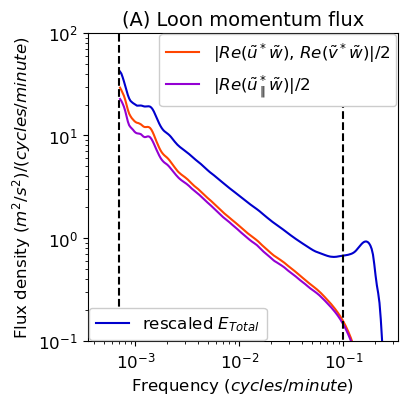

In [5]:
# Fig. 2A

fig, ax = plt.subplots(figsize=(4,4))
ymin = 1E-1
ymax = 1E2
line1, = ax.plot(frequency, flux_ReUVW_mean_spectrum, c=matplotlib.colors.CSS4_COLORS['orangered'],
                 label = r'|$Re(\tilde{u}^*\tilde{w})$, $Re(\tilde{v}^*\tilde{w})$|/2')
line2, = ax.plot(frequency, flux_ReUpW_mean_spectrum, c=matplotlib.colors.CSS4_COLORS['darkviolet'],
                 label = r'|$Re(\tilde{u}_\parallel^*\tilde{w})$|/2')
line3, = ax.plot(frequency, Etotal_scaled_mean_spectrum, c=matplotlib.colors.CSS4_COLORS['mediumblue'],
                 label = r'rescaled $E_{Total}$')
line4, = ax.plot([1/10, 1/10], [0, ymax],'--k',
                 label = '1/(10 min., 1 day)')
ax.plot([1/1440, 1/1440], [0, ymax],'--k')
ax.set_xlim(1/(2*24*60),1/3)
ax.set_ylim(ymin,ymax)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title('(A) Loon momentum flux', fontsize=14)
ax.set_xlabel('Frequency $(cycles/minute)$', fontsize=12)
ax.set_ylabel('Flux density $(m^{2}/s^{2})/(cycles/minute)$', fontsize=12)
ax.tick_params(labelsize=12)
first_legend = ax.legend(handles=[line1, line2], 
                         loc='upper right', bbox_to_anchor=(1.023, 1.024), framealpha=1, fontsize=12)
ax.add_artist(first_legend)
ax.legend(handles=[line3],
          loc='lower left', bbox_to_anchor=(-0.023, -0.024), framealpha=1, fontsize=12);
#plt.savefig('../plots/temp4a.pdf', format='pdf', bbox_inches='tight');

In [7]:
flights = pd.read_feather('Loon_momentum_fluxes_omega0_8_Ep.feather')

# Chop off the first and last two hours of each segment
def dt_start_end(segment):
    
    segment['dt_start'] = (segment.time - segment.time.iloc[0])/pd.Timedelta(1,'hours')
    segment['dt_end'] = (segment.time.iloc[-1] - segment.time)/pd.Timedelta(1,'hours')
    
    return segment

flights = flights.groupby('segment_id').progress_apply(dt_start_end)
flights = flights[flights.dt_start > 2]
flights = flights[flights.dt_end > 2]

# Delete depressurizations
flights = flights[flights.depressurization == 0]

  0%|          | 0/943 [00:00<?, ?it/s]

In [8]:
# Values in Table 1

print('Mean total momentum flux (mPa)')

temp = np.array(flights.flux_Etotal_scaled)
temp[temp == 0] = np.nan
print('from scaled Etotal:', np.nanmean(temp))

temp = np.array(flights.flux_Ep_scaled)
temp[temp == 0] = np.nan
print('from scaled Ep:', np.nanmean(temp))

temp = np.array(flights.flux_ReUVW)
temp[temp == 0] = np.nan
print('from Re(uw,vw):', np.nanmean(temp))

temp = np.array(flights.flux_AbsUVW)
temp[temp == 0] = np.nan
print('from Abs(uw,vw):', np.nanmean(temp))

temp = np.array(flights.flux_ReUpW)
temp[temp == 0] = np.nan
print('from Re(upw):', np.nanmean(temp))

temp = np.array(flights.flux_AbsUpW)
temp[temp == 0] = np.nan
print('from Abs(upw):', np.nanmean(temp))

print()
temp1 = np.array(flights.flux_ReUpW)
temp1[temp1 == 0] = np.nan
temp2 = np.array(flights.flux_AbsUpW)
temp2[temp2 == 0] = np.nan
temp = np.nanmean(temp1)/np.nanmean(temp2)
print('Ratio of Re(upw) to Abs(upw):', temp)
print('Effective phase error (degrees):', 180*np.arccos(temp)/np.pi)
temp3 = np.array(flights.flux_Etotal_scaled)
temp3[temp3 == 0] = np.nan
temp1a = np.nanmean(temp2) - np.nanmean(temp1)
temp2a = np.nanmean(temp3) - np.nanmean(temp1)
print('Percent of (scaled energy) - re(upw) explained by abs(upw) - re(upw):', 100*(temp1a/temp2a))

Mean total momentum flux (mPa)
from scaled Etotal: 13.731998884096086
from scaled Ep: 14.931921664201246
from Re(uw,vw): 6.541381799171225
from Abs(uw,vw): 10.029497631961627
from Re(upw): 5.806488854343539
from Abs(upw): 9.404242803544589

Ratio of Re(upw) to Abs(upw): 0.6174328944542982
Effective phase error (degrees): 51.871087786792096
Percent of (scaled energy) - re(upw) explained by abs(upw) - re(upw): 45.39460470928683


In [9]:
# Bin into latitude grid cells
lat_grid = -87.5 + 5*np.arange(36) # 5 deg., 90S to 90N
nlat_grid = lat_grid.size
dlat_grid = lat_grid[1] - lat_grid[0]
lat_grid_edges = lat_grid[0] - dlat_grid/2 + dlat_grid*np.arange(nlat_grid + 1)

flux_ReUVW_lat = np.nan*np.ones(shape=(nlat_grid))
flux_ReUpW_lat = np.nan*np.ones(shape=(nlat_grid))
flux_Etotal_lat = np.nan*np.ones(shape=(nlat_grid))
for i in np.arange(nlat_grid):
    
    temp = flights[flights.latitude >= lat_grid_edges[i]]
    temp = temp[temp.latitude < lat_grid_edges[i+1]]
    
    flux_ReUVW_lat[i] = np.nanmean(temp.flux_ReUVW)
    flux_ReUpW_lat[i] = np.nanmean(temp.flux_ReUpW)
    flux_Etotal_lat[i] = np.nanmean(temp.flux_Etotal_scaled)

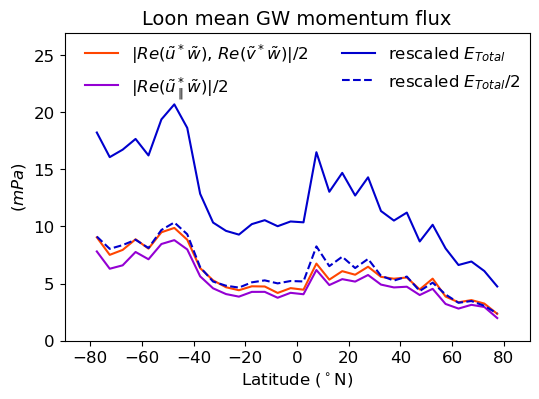

In [10]:
# Fig. S2

plt.figure(figsize=(6,4))
plt.plot(lat_grid,flux_ReUVW_lat,c=matplotlib.colors.CSS4_COLORS['orangered'])
plt.plot(lat_grid,flux_ReUpW_lat,c=matplotlib.colors.CSS4_COLORS['darkviolet'])
plt.plot(lat_grid,flux_Etotal_lat,c=matplotlib.colors.CSS4_COLORS['mediumblue'])
plt.plot(lat_grid,0.5*flux_Etotal_lat,c=matplotlib.colors.CSS4_COLORS['mediumblue'],
         linestyle='--')
plt.xlim(-90,90)
plt.ylim(0,27)
plt.title('Loon mean GW momentum flux', fontsize=14)
plt.xlabel(r'Latitude ($^\circ$N)', fontsize=12)
plt.ylabel(r'($mPa$)', fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend([r'|$Re(\tilde{u}^*\tilde{w})$, $Re(\tilde{v}^*\tilde{w})$|/2',
            r'|$Re(\tilde{u}_\parallel^*\tilde{w})$|/2',
            r'rescaled $E_{Total}$',
            r'rescaled $E_{Total}$/2'],
            loc='upper right', bbox_to_anchor=(1.013, 1.019), framealpha=0, ncol=2, fontsize=12);
#plt.savefig('../plots/temp5.pdf', format='pdf', bbox_inches='tight');